# IDC detection models by Louis VINCENT

### Model 1

Imports

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras import utils
import matplotlib.pyplot as plt
import seaborn as sns

Creating the test and validation datasets

In [4]:
img_height = 50
img_width = 50

batch_size = 64
seed = 42
validation_split = 0.2

train_ds = tf.keras.utils.image_dataset_from_directory(
    "./breast-cancer",
    batch_size=batch_size,
    image_size=(img_height, img_width),
    seed=seed,
    validation_split=validation_split,
    subset="training"
)

validation_ds = tf.keras.utils.image_dataset_from_directory(
    "./breast-cancer",
    batch_size=batch_size,
    image_size=(img_height, img_width),
    seed=seed,
    validation_split=validation_split,
    subset="validation"
)

Found 275222 files belonging to 2 classes.
Using 220178 files for training.


E0000 00:00:1791971450.462313    4198 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1791971450.465088   38052 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1791971450.490978    4198 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Found 275222 files belonging to 2 classes.
Using 55044 files for validation.


Let's check the classes and visualize a sample of the images

In [5]:
class_names = train_ds.class_names
print(class_names)

['IDC', 'non-IDC']


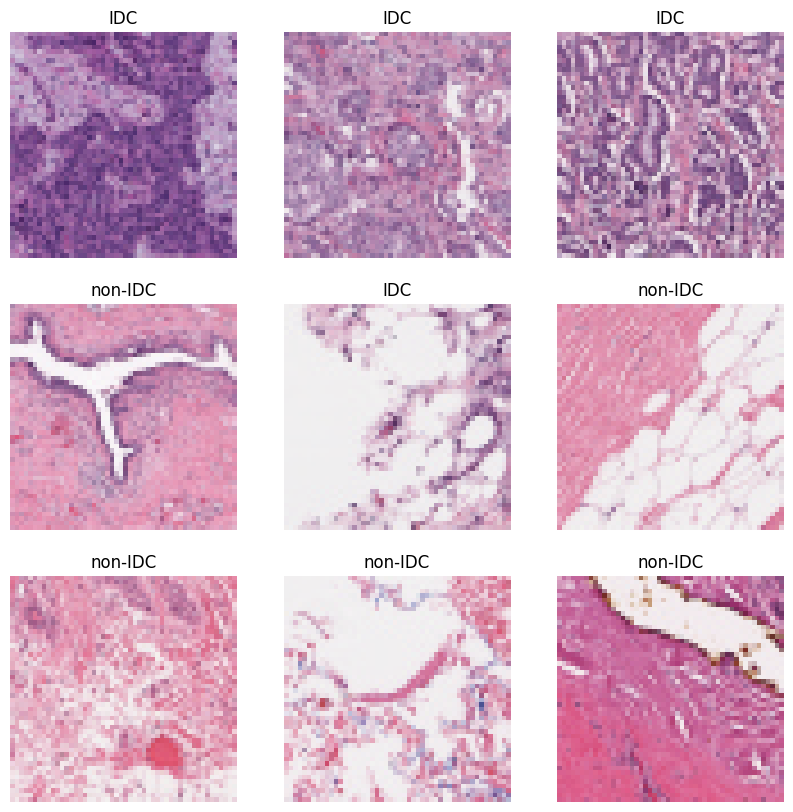

In [6]:
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

Defining the training sequence

In [7]:
num_classes = 2  # len(train_batch.class_names)

model = tf.keras.Sequential(
    [
        tf.keras.layers.Rescaling(1.0 / 255),
        tf.keras.layers.Conv2D(32, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(32, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(32, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(num_classes),
    ]
)

model.compile(
    optimizer="adam",
    loss=tf.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"],
)

In [8]:
history = model.fit(train_ds, validation_data=validation_ds, epochs=3)

Epoch 1/3


/home/vincent/5A_CPE/ML/.venv312/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


3441/3441 ━━━━━━━━━━━━━━━━━━━━ 48s 14ms/step - accuracy: 0.8304 - loss: 0.3905 - val_accuracy: 0.8500 - val_loss: 0.3529
Epoch 2/3
3441/3441 ━━━━━━━━━━━━━━━━━━━━ 44s 13ms/step - accuracy: 0.8512 - loss: 0.3502 - val_accuracy: 0.8520 - val_loss: 0.3438
Epoch 3/3
3441/3441 ━━━━━━━━━━━━━━━━━━━━ 46s 13ms/step - accuracy: 0.8581 - loss: 0.3335 - val_accuracy: 0.8656 - val_loss: 0.3182


In [9]:
print(model.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 50, 50, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 22, 22, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 11, 11, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 9, 9, 32)       │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 255,944 (999.79 KB)

 Trainable params: 85,314 (333.26 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 170,630 (666.53 KB)

None


Plot the loss and the accuracy

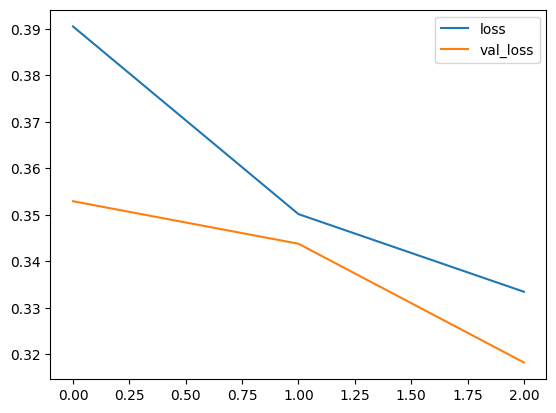

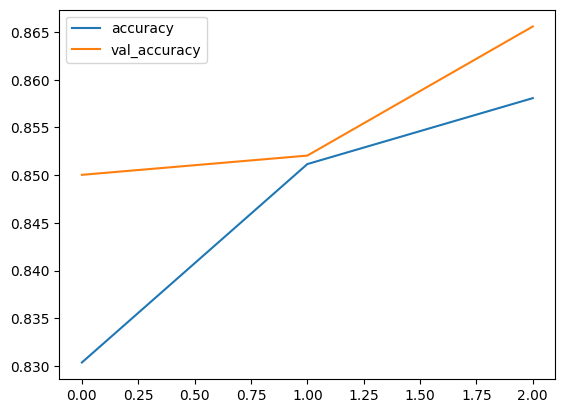

In [10]:
metrics = history.history
plt.plot(history.epoch, metrics["loss"], metrics["val_loss"])
plt.legend(["loss", "val_loss"])
plt.show()

plt.plot(history.epoch, metrics["accuracy"], metrics["val_accuracy"])
plt.legend(["accuracy", "val_accuracy"])
plt.show()

Show the prediction confusion matrix

In [11]:
test_images = []
test_labels = []

for images, labels in validation_ds:
    for i in range(len(images)):
        test_images.append(images[i].numpy())
        test_labels.append(labels[i].numpy())

test_images = np.array(test_images)
test_labels = np.array(test_labels)

image_predictions = np.argmax(model.predict(test_images), axis=1)

1721/1721 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step


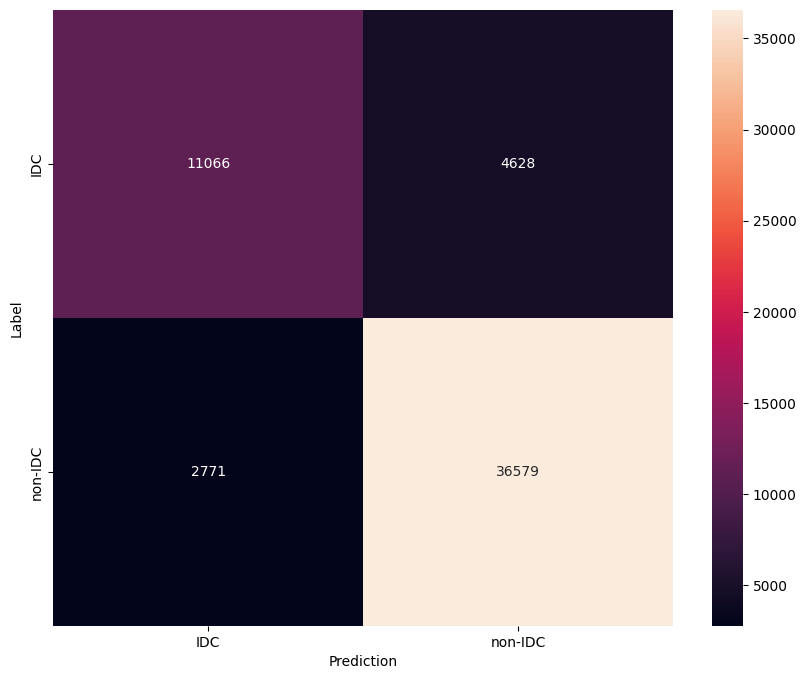

In [12]:
confusion_mtx = tf.math.confusion_matrix(test_labels, image_predictions)
plt.figure(figsize=(10, 8))
sns.heatmap(
    confusion_mtx,
    xticklabels=train_ds.class_names,
    yticklabels=train_ds.class_names,
    annot=True,
    fmt="g",
)
plt.xlabel("Prediction")
plt.ylabel("Label")
plt.show()